正在计算各组织的 P 值...
p_score.csv 已生成。


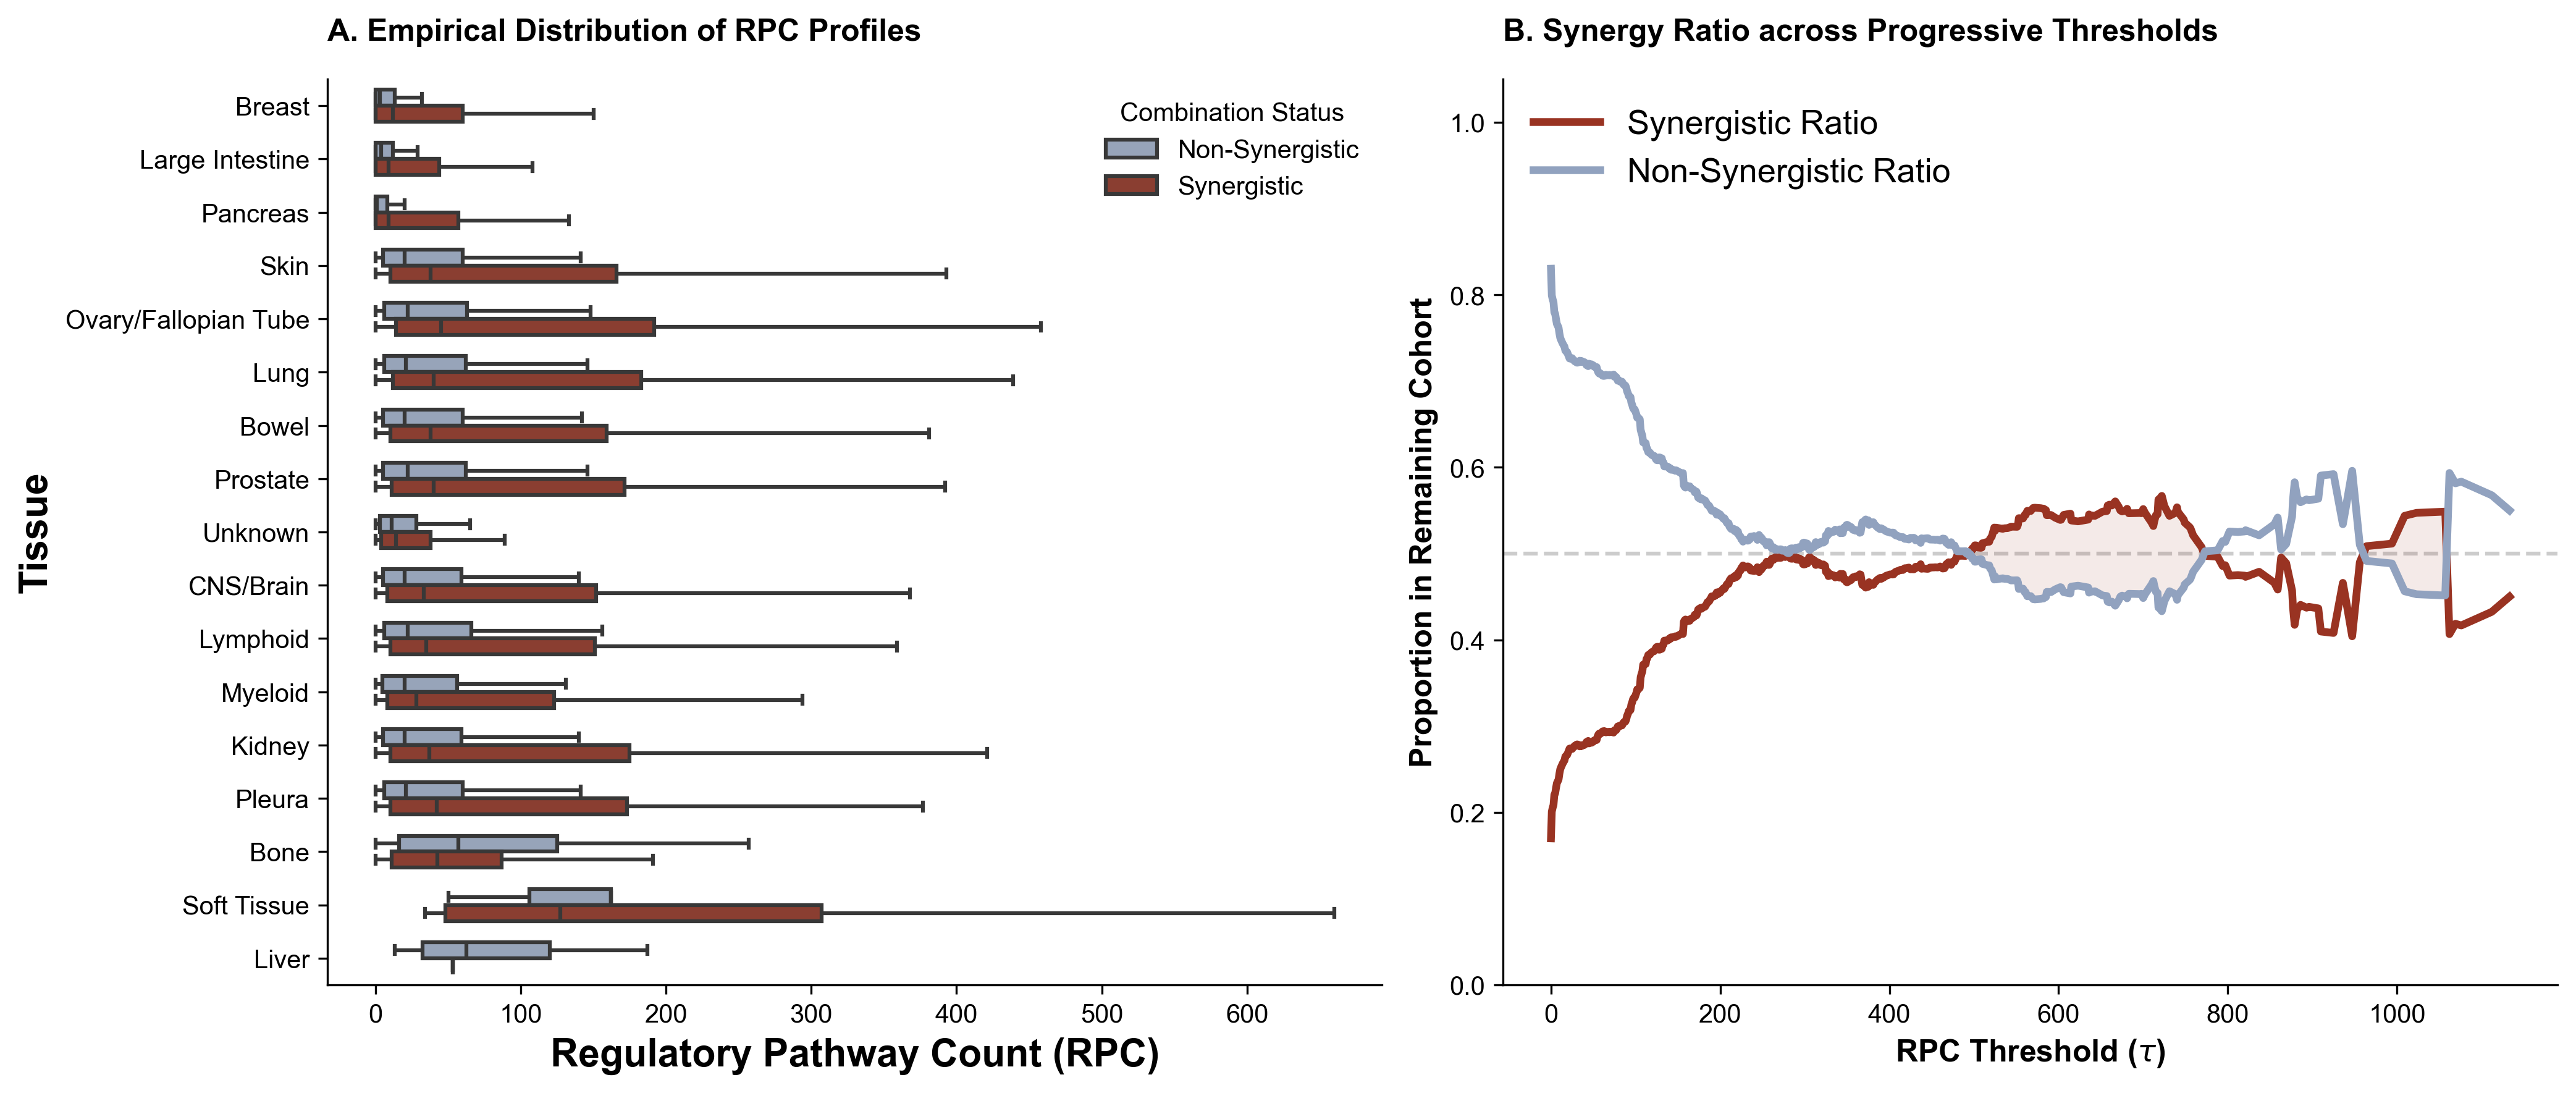

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# 1. 自动计算 P 值并生成 p_score.csv
# ==========================================
print("正在计算各组织的 P 值...")
# 读取原始测序/通路映射数据
df_raw = pd.read_csv("gene_path_path.csv")

# 统一 Synergy? 列的数据类型为布尔值或标准字符串
df_raw["Synergy_bool"] = (
    df_raw["Synergy?"].astype(str).str.upper().map({"TRUE": True, "FALSE": False})
)

p_results = []
for tissue, group in df_raw.groupby("Tissue"):
    # 提取两组的 RPC (Related Pathways) 数据
    syn_rpc = group[group["Synergy_bool"] == True]["Related Pathways"].dropna()
    nonsyn_rpc = group[group["Synergy_bool"] == False]["Related Pathways"].dropna()

    # 执行独立样本 t 检验 (假设方差不齐，使用 Welch's t-test)
    if len(syn_rpc) >= 2 and len(nonsyn_rpc) >= 2:
        t_stat, p_val = stats.ttest_ind(syn_rpc, nonsyn_rpc, equal_var=False)
    else:
        p_val = np.nan  # 数据不足无法计算

    p_results.append(
        {"Tissue": tissue, "average_p_value": p_val, "row_count": len(group)}
    )

# 保存 P 值结果，供后续表格或其他分析使用
df_p = pd.DataFrame(p_results)
df_p.to_csv("p_score.csv", index=False)
print("p_score.csv 已生成。")

# ==========================================
# 2. 顶会风格绘图 (应用你的专属配色)
# ==========================================
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica"]
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# 你的专属配色
COLOR_SYNERGY = "#993322"  # 深红
COLOR_NOT_SYN = "#91A2BF"  # 灰蓝
COLOR_THRESHOLD = "#2C3EA0"  # 深蓝 (用于辅助线)

# 过滤掉无效数据以进行绘图
df_plot = df_raw.dropna(subset=["Related Pathways", "Synergy_bool"]).copy()

# 创建 1x2 布局的画布
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

# ----------------------------------------------------
# Panel A: 经验分布 (水平箱线图)
# ----------------------------------------------------
# 绘制箱线图，showfliers=False 隐藏极端异常值使主体分布更清晰
sns.boxplot(
    data=df_plot,
    y="Tissue",
    x="Related Pathways",
    hue="Synergy_bool",
    palette={True: COLOR_SYNERGY, False: COLOR_NOT_SYN},
    ax=ax1,
    showfliers=False,
    width=0.6,
    linewidth=1.5,
)

ax1.set_xlabel("Regulatory Pathway Count (RPC)", fontsize=15, fontweight="bold")
ax1.set_ylabel("Tissue", fontsize=15, fontweight="bold")
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# 自定义图例
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(
    handles,
    ["Non-Synergistic", "Synergistic"],
    title="Combination Status",
    loc="upper right",
    frameon=False,
)
ax1.set_title(
    "A. Empirical Distribution of RPC Profiles", loc="left", fontweight="bold", pad=15
)

# ----------------------------------------------------
# Panel B: 阈值分布比例分析 (Threshold-Distribution Analysis)
# ----------------------------------------------------
# 提取唯一的 RPC 值作为候选阈值 tau
taus = sorted(df_plot["Related Pathways"].unique())
syn_ratios = []
nonsyn_ratios = []
valid_taus = []

for tau in taus:
    # 筛选出 RPC >= tau 的所有组合
    subset = df_plot[df_plot["Related Pathways"] >= tau]
    total_at_tau = len(subset)

    # 保证该阈值下仍有足够的数据点(比如至少10个)，避免曲线尾部震荡
    if total_at_tau > 10:
        syn_count = len(subset[subset["Synergy_bool"] == True])
        nonsyn_count = len(subset[subset["Synergy_bool"] == False])

        syn_ratios.append(syn_count / total_at_tau)
        nonsyn_ratios.append(nonsyn_count / total_at_tau)
        valid_taus.append(tau)

# 绘制平滑的曲线或折线
ax2.plot(
    valid_taus, syn_ratios, color=COLOR_SYNERGY, linewidth=3, label="Synergistic Ratio"
)
ax2.plot(
    valid_taus,
    nonsyn_ratios,
    color=COLOR_NOT_SYN,
    linewidth=3,
    label="Non-Synergistic Ratio",
)

# 填充两条线之间的区域，增强视觉冲击力 (呼应 "statistical divergence")
ax2.fill_between(
    valid_taus,
    syn_ratios,
    nonsyn_ratios,
    where=(np.array(syn_ratios) > np.array(nonsyn_ratios)),
    interpolate=True,
    color=COLOR_SYNERGY,
    alpha=0.1,
)

ax2.set_xlabel(r"RPC Threshold ($\tau$)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Proportion in Remaining Cohort", fontsize=12, fontweight="bold")
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.set_ylim(0, 1.05)

# 绘制50%基准线
ax2.axhline(0.5, color="#CCCCCC", linestyle="--", linewidth=1.5, zorder=0)

ax2.legend(loc="upper left", frameon=False, fontsize=13)
ax2.set_title(
    "B. Synergy Ratio across Progressive Thresholds",
    loc="left",
    fontweight="bold",
    pad=15,
)

# ==========================================
# 3. 调整与保存
# ==========================================
plt.tight_layout()
plt.savefig("Hypergraph_RPC_Analysis.pdf", bbox_inches="tight", transparent=True)
plt.savefig(
    "Hypergraph_RPC_Analysis.png", dpi=300, bbox_inches="tight", transparent=True
)
plt.show()